开始训练（仅用 0~920h 数据）...
训练完成！
开始盲测，强迫它凭空推演 14000 步...
🚨 纯盲测（13000步）的 RMSE: 0.027519 V
（你会发现这个值巨大，因为直线根本跟不上真实的断崖下跌。）


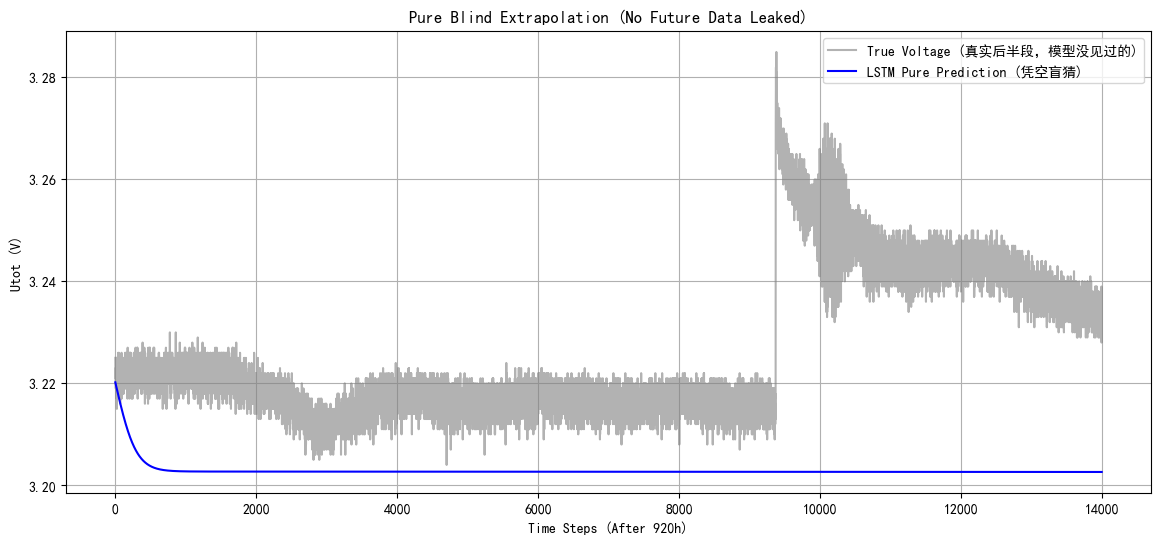

In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ================= 1. 读取【纯训练集】 =================
# 这个文件里只有 0~920h 的数据，绝对没有未来！
file_path = r'C:\Users\YOGA\Desktop\测试集.csv'
df_train_only = pd.read_csv(file_path)

# 提取时间和电压
data_train = df_train_only[['Time (h)', 'Utot (V)']].values

# 归一化：这里可以直接 fit_transform 了，因为数据里绝对没有未来
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(data_train)

# ================= 2. 训练模型 =================
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        xs.append(data[i : i + seq_length])
        ys.append(data[i + seq_length, 1])
    return np.array(xs), np.array(ys)

SEQ_LENGTH = 100
X_train_lstm, y_train_lstm = create_sequences(train_scaled, SEQ_LENGTH)
X_train_tensor = torch.FloatTensor(X_train_lstm)
y_train_tensor = torch.FloatTensor(y_train_lstm).unsqueeze(1)

class VoltageLSTM(nn.Module):
    def __init__(self, input_size=2, hidden_size=32, num_layers=1, output_size=1):
        super(VoltageLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)
    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out

model = VoltageLSTM()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=512, shuffle=True)

print("开始训练（仅用 0~920h 数据）...")
epochs = 15
for epoch in range(epochs):
    model.train()
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
print("训练完成！")

# ================= 3. 纯盲测外推 =================
model.eval()
with torch.no_grad():
    seed = torch.FloatTensor(train_scaled[-SEQ_LENGTH:]).unsqueeze(0)

    # 【硬性规定】让它往后预测 13000 步（大致等于剩下的 20% 长度）
    steps_to_predict = 14000

    predicted_voltages = []
    current_input = seed

    time_diff = data_train[1, 0] - data_train[0, 0]
    current_time = data_train[-1, 0]

    print(f"开始盲测，强迫它凭空推演 {steps_to_predict} 步...")
    for _ in range(steps_to_predict):
        pred_y = model(current_input)
        predicted_voltages.append(pred_y.item())

        current_time += time_diff
        next_time_scaled = scaler.transform([[current_time, 0]])[0, 0]
        next_step = torch.FloatTensor([[[next_time_scaled, pred_y.item()]]])

        current_input = torch.cat((current_input[:, 1:, :], next_step), dim=1)

# 把预测值反归一化成真实电压
dummy = np.zeros((len(predicted_voltages), 2))
dummy[:, 1] = predicted_voltages
predictions_real = scaler.inverse_transform(dummy)[:, 1]

# ================= 4. 读取真实未来数据（仅用于画图对比） =================
# 为了让你亲眼看到它错得有多离谱，我们才去读完整数据
df_full = pd.read_csv(r'C:\Users\YOGA\Desktop\电池ai分析\IEEE2014DataChallengeData\IEEE 2014 Data Challenge Data\FC1_Without_Ripples\FC1.csv')
split_idx = len(df_train_only) # 训练集的长度
true_future = df_full['Utot (V)'].values[split_idx : split_idx + steps_to_predict]

from sklearn.metrics import mean_squared_error
import math

# 确保长度对齐（因为可能有一些边角料没切干净）
min_len = min(len(predictions_real), len(true_future))
rmse_blind = math.sqrt(mean_squared_error(true_future[:min_len], predictions_real[:min_len]))

print(f"🚨 纯盲测（13000步）的 RMSE: {rmse_blind:.6f} V")
print("（你会发现这个值巨大，因为直线根本跟不上真实的断崖下跌。）")

# ================= 5. 画图 =================
plt.figure(figsize=(14, 6))
plt.plot(range(len(true_future)), true_future, label='True Voltage (真实后半段，模型没见过的)', color='gray', alpha=0.6)
plt.plot(range(len(predictions_real)), predictions_real, label='LSTM Pure Prediction (凭空盲猜)', color='blue')
plt.title('Pure Blind Extrapolation (No Future Data Leaked)')
plt.xlabel('Time Steps (After 920h)')
plt.ylabel('Utot (V)')
plt.legend()
plt.grid(True)
plt.show()